In [1]:
import numpy as np
import pandas as pd
import itertools
import random
import tensorflow as tf
import torch
import torch.nn as nn
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Input, Dense, Dropout, BatchNormalization,Conv1D, MaxPooling1D, GlobalAveragePooling1D, GRU)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import (train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,precision_score,f1_score,roc_auc_score,recall_score)
from scipy.stats import randint, uniform
from xgboost import XGBClassifier
from BorutaShap import BorutaShap
from kan import KAN
import torch.nn.functional as F
from scipy.stats import uniform, randint
from collections import Counter
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import os
import joblib
import cloudpickle
from kan import MultKAN
from sklearn.base import BaseEstimator, ClassifierMixin

In [2]:
df = pd.read_excel(
    r'C:\Users\65163\Desktop\python\NHANES_Diabetes\2017-2020\NHANES_2017_2020_Modeling_Candidates_DropNA_v2.xlsx',
    sheet_name='DropNA_Data'
)


x = df.drop(columns=['Diabetes'])
y = df['Diabetes']


continuous_features = [
    "RIDAGEYR",
    "INDFMPIR",
    "BMXWT",
    "BMXHT",
    "BMXBMI",
    "BMXWAIST",
    "BMXARMC",
    "LBXIN",
    "LBDHDD",
    "LBXTC",
    "LBXSAL",
    "LBXSATSI",
    "LBXSASSI",
    "LBXSGTSI",
    "LBXSAPSI",
    "LBXSCR",
    "LBXSBU",
    "LBXSUA",
    "LBXTR",
    "LBDLDLN",
    "URDACT",
    "LBXWBCSI",
    "LBXRBCSI",
    "LBXHGB",
    "LBXMCVSI",
    "LBXRDW",
    "LBXPLTSI",
    "PAD680",
    "SLD012",
    "SLD013",
    "SBP_MEAN",
    "DBP_MEAN",
    'UACR'
]

categorical_features = [
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "BPQ020",
    "BPQ080",
    "ALQ121",
    "PAQ605",
    "PAQ620",
    "PAQ635",
    "PAQ650",
    "PAQ665",
    "DBQ700",
    "KIQ022",
    "Smoking_Status"
]



print("Dataset Information")

print("X shape:", x.shape)
print("Y shape:", y.shape)

print("\nContinuous features:", len(continuous_features))
print(continuous_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)


all_features = continuous_features + categorical_features

missing_features = [
    col for col in all_features
    if col not in x.columns
]

if missing_features:
    print("\nMissing features:", missing_features)


unclassified_features = [
    col for col in x.columns
    if col not in all_features
]

if unclassified_features:
    print("\nUnclassified features:", unclassified_features)

if len(all_features) != len(set(all_features)):
    print("\nWarning: Duplicate feature definitions!")

print("\nTotal classified features:", len(all_features))
print("Total predictors:", x.shape[1])
print("Missing values in X:", x.isna().sum().sum())
print("Target distribution:")
print(y.value_counts())

Dataset Information
X shape: (2572, 47)
Y shape: (2572,)

Continuous features: 33
['RIDAGEYR', 'INDFMPIR', 'BMXWT', 'BMXHT', 'BMXBMI', 'BMXWAIST', 'BMXARMC', 'LBXIN', 'LBDHDD', 'LBXTC', 'LBXSAL', 'LBXSATSI', 'LBXSASSI', 'LBXSGTSI', 'LBXSAPSI', 'LBXSCR', 'LBXSBU', 'LBXSUA', 'LBXTR', 'LBDLDLN', 'URDACT', 'LBXWBCSI', 'LBXRBCSI', 'LBXHGB', 'LBXMCVSI', 'LBXRDW', 'LBXPLTSI', 'PAD680', 'SLD012', 'SLD013', 'SBP_MEAN', 'DBP_MEAN', 'UACR']

Categorical features: 14
['RIAGENDR', 'RIDRETH3', 'DMDEDUC2', 'BPQ020', 'BPQ080', 'ALQ121', 'PAQ605', 'PAQ620', 'PAQ635', 'PAQ650', 'PAQ665', 'DBQ700', 'KIQ022', 'Smoking_Status']

Total classified features: 47
Total predictors: 47
Missing values in X: 0
Target distribution:
Diabetes
1    1762
0     810
Name: count, dtype: int64


In [3]:
#  Descriptive statistics for continuous features

continuous_summary = df[continuous_features].describe().T

continuous_summary = continuous_summary[
    ["count", "mean", "std", "50%", "min", "max"]
]

continuous_summary = continuous_summary.rename(columns={
    "count": "N",
    "mean": "Mean",
    "std": "SD",
    "50%": "Median",
    "min": "Min",
    "max": "Max"
})

continuous_summary = continuous_summary.round(3)

print("\nContinuous Variables - Overall")
display(continuous_summary)


Continuous Variables - Overall


,N,Mean,SD,Median,Min,Max
RIDAGEYR,2572.0,49.924,17.042,51.000,20.000,80.000
INDFMPIR,2572.0,2.696,1.632,2.390,0.000,5.000
BMXWT,2572.0,84.781,22.603,81.800,39.800,204.600
BMXHT,2572.0,167.917,9.737,167.600,141.400,198.700
BMXBMI,2572.0,29.997,7.372,28.800,15.500,67.000
BMXWAIST,2572.0,101.217,17.408,99.600,63.200,178.000
BMXARMC,2572.0,33.922,5.300,33.500,20.100,57.200
LBXIN,2572.0,14.748,24.507,9.920,0.710,512.500
LBDHDD,2572.0,53.595,16.063,51.000,21.000,187.000
LBXTC,2572.0,183.632,41.943,179.000,77.000,446.000


In [4]:

categorical_summary = []

# Include y (Diabetes)
all_categorical_features = categorical_features + ["Diabetes"]

for col in all_categorical_features:

    counts = df[col].value_counts(dropna=False)

    percentages = (
        df[col].value_counts(normalize=True, dropna=False) * 100
    )

    # Format category values
    categories = [
        f"{category:.2f}".rstrip("0").rstrip(".")
        if isinstance(category, (float, np.floating))
        and pd.notna(category)
        else str(category)
        for category in counts.index
    ]

    categorical_summary.append({
        "Variable": col,
        "Category": " / ".join(categories),
        "n": " / ".join(map(str, counts.values)),
        "%": " / ".join(
            [f"{percentages[category]:.1f}" for category in counts.index]
        )
    })


categorical_summary = pd.DataFrame(categorical_summary).reset_index(drop=True)

print("\nCategorical Variables - Descriptive Statistics")

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_columns", None,
    "display.width", None
):
    display(categorical_summary.style.hide(axis="index"))


Categorical Variables - Descriptive Statistics


Variable,Category,n,%
RIAGENDR,1 / 2,1322 / 1250,51.4 / 48.6
RIDRETH3,3 / 4 / 1 / 2 / 6 / 7,981 / 641 / 318 / 242 / 240 / 150,38.1 / 24.9 / 12.4 / 9.4 / 9.3 / 5.8
DMDEDUC2,4 / 5 / 3 / 2 / 1,903 / 662 / 610 / 264 / 133,35.1 / 25.7 / 23.7 / 10.3 / 5.2
BPQ020,2 / 1,1605 / 967,62.4 / 37.6
BPQ080,2 / 1,1627 / 945,63.3 / 36.7
ALQ121,0 / 6 / 10 / 9 / 4 / 5 / 7 / 3 / 8 / 2 / 1,547 / 355 / 273 / 265 / 204 / 196 / 191 / 174 / 151 / 116 / 100,21.3 / 13.8 / 10.6 / 10.3 / 7.9 / 7.6 / 7.4 / 6.8 / 5.9 / 4.5 / 3.9
PAQ605,2 / 1,1872 / 700,72.8 / 27.2
PAQ620,2 / 1,1383 / 1189,53.8 / 46.2
PAQ635,2 / 1,1989 / 583,77.3 / 22.7
PAQ650,2 / 1,1925 / 647,74.8 / 25.2


In [5]:
#Data splitting

seed = 123456789

X_train_set, X_test_set, y_train_set, y_test_set = train_test_split(
    x,
    y,
    test_size=0.2,
    stratify=y,
    random_state=seed
)

In [6]:
# Initialize XGBoost classifier
xgb = XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    use_label_encoder=False,
    random_state=seed,
    n_jobs=1
)

# Define hyperparameter search space
param_dist = {
    'n_estimators': randint(100, 500),        
    'max_depth': randint(3, 10),              
    'learning_rate': uniform(0.01, 0.19),     
    'subsample': uniform(0.6, 0.4),           
    'colsample_bytree': uniform(0.6, 0.4),    
    'gamma': uniform(0, 0.5),                 
    'min_child_weight': randint(1, 10)        
}

# Stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=seed
)

# Randomized search for hyperparameter tuning
random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=300,                
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1,
    random_state=seed
)

random_search.fit(X_train_set, y_train_set)

print("Best parameters:")
print(random_search.best_params_)

print("Best CV AUC:")
print(random_search.best_score_)

Fitting 5 folds for each of 300 candidates, totalling 1500 fits
Best parameters:
{'colsample_bytree': np.float64(0.7202137684438428), 'gamma': np.float64(0.06347455070583691), 'learning_rate': np.float64(0.011435697327894706), 'max_depth': 3, 'min_child_weight': 6, 'n_estimators': 436, 'subsample': np.float64(0.9296888868448961)}
Best CV AUC:
0.8251344471876395


In [7]:
# Use the best hyperparameters from RandomizedSearchCV

best_params = random_search.best_params_
xgb_model = XGBClassifier(
    **best_params,
    random_state=seed,
    use_label_encoder=False,
    eval_metric="logloss",
    n_jobs=1,          
)

# Stratified 5-fold cross-validation

kf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=seed
    
)

fold_selected_features = {}
feature_importance_dict = {} 

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_train_set, y_train_set)
    ):
    print(f"\nFold {fold + 1} ----------------")

    X_train = X_train_set.iloc[train_idx]
    y_train = y_train_set.iloc[train_idx]

    feature_selector = BorutaShap(
        model=xgb_model,
        importance_measure="shap",
        classification=True
    )

    feature_selector.fit(
        X=X_train,
        y=y_train,
        n_trials=200,
        random_state=seed
    )

    selected_features = feature_selector.accepted
    fold_selected_features[fold] = selected_features

    print(f"Selected features ({len(selected_features)}):")
    print(selected_features)
    xgb_model.fit(X_train, y_train)
    importances = xgb_model.feature_importances_

    for f, v in zip(X_train.columns, importances):
        feature_importance_dict.setdefault(f, []).append(v)


Fold 1 ----------------


  0%|          | 0/200 [00:00<?, ?it/s]

9 attributes confirmed important: ['LBDHDD', 'BMXWAIST', 'LBXRDW', 'LBXIN', 'RIDAGEYR', 'BPQ020', 'LBXSGTSI', 'SBP_MEAN', 'LBXRBCSI']
37 attributes confirmed unimportant: ['LBXSAL', 'PAQ665', 'LBXSASSI', 'KIQ022', 'BMXARMC', 'Smoking_Status', 'PAD680', 'BPQ080', 'DBQ700', 'LBDLDLN', 'URDACT', 'RIAGENDR', 'BMXHT', 'PAQ635', 'PAQ605', 'LBXHGB', 'LBXPLTSI', 'BMXWT', 'LBXTR', 'BMXBMI', 'SLD013', 'LBXTC', 'DBP_MEAN', 'RIDRETH3', 'LBXSCR', 'LBXSAPSI', 'LBXSBU', 'ALQ121', 'LBXSUA', 'PAQ620', 'DMDEDUC2', 'UACR', 'LBXSATSI', 'LBXMCVSI', 'SLD012', 'PAQ650', 'INDFMPIR']
1 tentative attributes remains: ['LBXWBCSI']
Selected features (9):
['LBDHDD', 'BMXWAIST', 'LBXRDW', 'LBXIN', 'RIDAGEYR', 'BPQ020', 'LBXSGTSI', 'SBP_MEAN', 'LBXRBCSI']

Fold 2 ----------------


  0%|          | 0/200 [00:00<?, ?it/s]

9 attributes confirmed important: ['LBDHDD', 'URDACT', 'BMXWAIST', 'LBXIN', 'RIDAGEYR', 'LBXSGTSI', 'LBXSBU', 'SBP_MEAN', 'LBXRBCSI']
37 attributes confirmed unimportant: ['LBXSAL', 'PAQ665', 'LBXSASSI', 'KIQ022', 'BMXARMC', 'Smoking_Status', 'PAD680', 'BPQ080', 'DBQ700', 'LBDLDLN', 'RIAGENDR', 'LBXRDW', 'BMXHT', 'PAQ635', 'PAQ605', 'LBXHGB', 'LBXPLTSI', 'BMXWT', 'LBXTR', 'BMXBMI', 'SLD013', 'LBXTC', 'DBP_MEAN', 'RIDRETH3', 'LBXSCR', 'LBXSAPSI', 'ALQ121', 'LBXSUA', 'PAQ620', 'DMDEDUC2', 'UACR', 'LBXSATSI', 'LBXMCVSI', 'SLD012', 'LBXWBCSI', 'PAQ650', 'INDFMPIR']
1 tentative attributes remains: ['BPQ020']
Selected features (9):
['LBDHDD', 'URDACT', 'BMXWAIST', 'LBXIN', 'RIDAGEYR', 'LBXSGTSI', 'LBXSBU', 'SBP_MEAN', 'LBXRBCSI']

Fold 3 ----------------


  0%|          | 0/200 [00:00<?, ?it/s]

9 attributes confirmed important: ['LBDHDD', 'RIAGENDR', 'BMXWAIST', 'BPQ080', 'LBXIN', 'RIDAGEYR', 'BMXARMC', 'SBP_MEAN', 'LBXRBCSI']
36 attributes confirmed unimportant: ['LBXSAL', 'PAQ665', 'LBXSASSI', 'KIQ022', 'LBXSGTSI', 'Smoking_Status', 'PAD680', 'DBQ700', 'LBXRDW', 'BMXHT', 'PAQ635', 'PAQ605', 'BPQ020', 'LBXHGB', 'LBXPLTSI', 'BMXWT', 'LBXTR', 'BMXBMI', 'SLD013', 'LBXTC', 'DBP_MEAN', 'RIDRETH3', 'LBXSCR', 'LBXSAPSI', 'LBXSBU', 'ALQ121', 'LBXSUA', 'PAQ620', 'DMDEDUC2', 'UACR', 'LBXSATSI', 'LBXMCVSI', 'SLD012', 'LBXWBCSI', 'PAQ650', 'INDFMPIR']
2 tentative attributes remains: ['LBDLDLN', 'URDACT']
Selected features (9):
['LBDHDD', 'RIAGENDR', 'BMXWAIST', 'BPQ080', 'LBXIN', 'RIDAGEYR', 'BMXARMC', 'SBP_MEAN', 'LBXRBCSI']

Fold 4 ----------------


  0%|          | 0/200 [00:00<?, ?it/s]

10 attributes confirmed important: ['LBDHDD', 'URDACT', 'RIAGENDR', 'BMXWAIST', 'LBXIN', 'RIDAGEYR', 'BPQ020', 'SBP_MEAN', 'LBXRBCSI', 'BMXWT']
36 attributes confirmed unimportant: ['LBXSAL', 'PAQ665', 'LBXSASSI', 'KIQ022', 'LBXSGTSI', 'BMXARMC', 'Smoking_Status', 'BPQ080', 'DBQ700', 'LBDLDLN', 'LBXRDW', 'BMXHT', 'PAQ635', 'PAQ605', 'LBXHGB', 'LBXPLTSI', 'LBXTR', 'SLD013', 'BMXBMI', 'LBXTC', 'DBP_MEAN', 'RIDRETH3', 'LBXSCR', 'LBXSAPSI', 'LBXSBU', 'ALQ121', 'LBXSUA', 'PAQ620', 'DMDEDUC2', 'UACR', 'LBXSATSI', 'LBXMCVSI', 'SLD012', 'LBXWBCSI', 'PAQ650', 'INDFMPIR']
1 tentative attributes remains: ['PAD680']
Selected features (10):
['LBDHDD', 'URDACT', 'RIAGENDR', 'BMXWAIST', 'LBXIN', 'RIDAGEYR', 'BPQ020', 'SBP_MEAN', 'LBXRBCSI', 'BMXWT']

Fold 5 ----------------


  0%|          | 0/200 [00:00<?, ?it/s]

10 attributes confirmed important: ['LBDHDD', 'BMXWAIST', 'LBXIN', 'RIDAGEYR', 'LBXMCVSI', 'BPQ020', 'LBXSGTSI', 'LBXSBU', 'SBP_MEAN', 'LBXRBCSI']
35 attributes confirmed unimportant: ['LBXSAL', 'PAQ665', 'LBXSASSI', 'KIQ022', 'BMXARMC', 'Smoking_Status', 'PAD680', 'BPQ080', 'DBQ700', 'LBDLDLN', 'URDACT', 'RIAGENDR', 'BMXHT', 'PAQ635', 'PAQ605', 'LBXHGB', 'LBXPLTSI', 'LBXTR', 'BMXWT', 'BMXBMI', 'SLD013', 'LBXTC', 'DBP_MEAN', 'RIDRETH3', 'LBXSCR', 'LBXSAPSI', 'ALQ121', 'LBXSUA', 'PAQ620', 'UACR', 'LBXSATSI', 'SLD012', 'LBXWBCSI', 'PAQ650', 'INDFMPIR']
2 tentative attributes remains: ['DMDEDUC2', 'LBXRDW']
Selected features (10):
['LBDHDD', 'BMXWAIST', 'LBXIN', 'RIDAGEYR', 'LBXMCVSI', 'BPQ020', 'LBXSGTSI', 'LBXSBU', 'SBP_MEAN', 'LBXRBCSI']


In [8]:
#The final selected features

all_features = []
for feats in fold_selected_features.values():
    all_features.extend(feats)

feature_counter = Counter(all_features)

feature_freq = {
    k: v / kf.n_splits
    for k, v in feature_counter.items()
}

final_features = [
    k for k, v in feature_freq.items() if v >= 0.6
]


mean_importance = {
    f: np.mean(v)
    for f, v in feature_importance_dict.items()
}



final_features_sorted = sorted(
    final_features,
    key=lambda x: (feature_freq[x], mean_importance.get(x, 0)),
    reverse=True
)

print("\nFinal selected features (sorted):")
print(final_features_sorted)


Final selected features (sorted):
['BMXWAIST', 'RIDAGEYR', 'LBXIN', 'SBP_MEAN', 'LBDHDD', 'LBXRBCSI', 'BPQ020', 'LBXSGTSI']


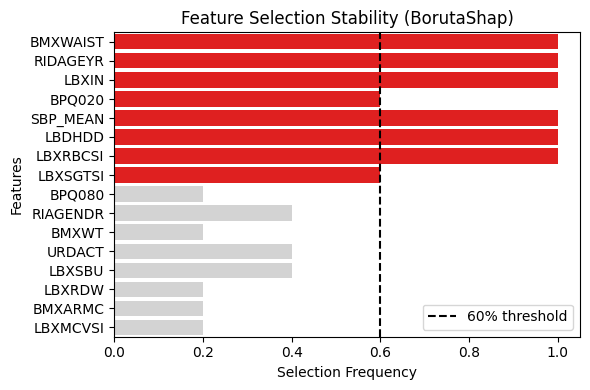

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns


freq_df = pd.DataFrame.from_dict(
    feature_freq, orient="index", columns=["Frequency"]
)


freq_df["Importance"] = freq_df.index.map(mean_importance)

freq_df["Selected"] = freq_df.index.isin(final_features)

freq_df = freq_df.sort_values(
    by=["Selected", "Importance"],
    ascending=[False, False]
)

colors = freq_df["Selected"].map({True: "red", False: "lightgray"})


plt.figure(figsize=(6, 4))

sns.barplot(
    data=freq_df,
    x="Frequency",
    y=freq_df.index,
    palette=colors.tolist()
)

plt.axvline(0.6, linestyle="--", color="black", label="60% threshold")

plt.xlabel("Selection Frequency")
plt.ylabel("Features")
plt.title("Feature Selection Stability (BorutaShap)")
plt.legend()
plt.tight_layout()

plt.savefig("BorutaSHAP_feature_selection.png", dpi=300)
plt.show()

In [10]:
# Set random seed
os.environ["PYTHONHASHSEED"] = str(seed)
random.seed(seed)
np.random.seed(seed)
tf.keras.utils.set_random_seed(seed)
torch.manual_seed(seed)

In [11]:
#  Define base models
# 1. MLP

def build_mlp(
    input_dim,
    seed,
    hidden_1=128,
    hidden_2=64,
    dropout=0.2,
    learning_rate=0.001
):

    tf.keras.utils.set_random_seed(seed)

    model_deep = Sequential([
        Input(shape=(input_dim,)),

        Dense(
            hidden_1,
            activation='relu',
            kernel_regularizer=l2(1e-4)
        ),

        BatchNormalization(),
        Dropout(dropout),

        Dense(
            hidden_2,
            activation='relu',
            kernel_regularizer=l2(1e-4)
        ),

        BatchNormalization(),
        Dropout(dropout),

        Dense(1, activation='sigmoid')
    ])

    model_deep.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            tf.keras.metrics.AUC(name='auc')
        ]
    )

    return model_deep


# 2. CNN


def build_cnn(
    input_len,
    seed,
    filters=32,
    dropout=0.3,
    dense_units=32,
    learning_rate=0.001
):

    tf.keras.utils.set_random_seed(seed)

    model_deep = Sequential([
        Input(shape=(input_len, 1)),

        Conv1D(
            filters,
            3,
            activation='relu',
            padding='same'
        ),

        MaxPooling1D(2),

        Conv1D(
            filters,
            3,
            activation='relu',
            padding='same'
        ),

        GlobalAveragePooling1D(),

        Dropout(dropout),

        Dense(
            dense_units,
            activation='relu'
        ),

        Dense(1, activation='sigmoid')
    ])

    model_deep.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            tf.keras.metrics.AUC(name='auc')
        ]
    )

    return model_deep


# 3. GRU

def build_gru(
    input_len,
    seed,
    gru_units=32,
    dropout=0.2,
    dense_units=32,
    learning_rate=0.001
):

    tf.keras.utils.set_random_seed(seed)

    model_deep = Sequential([
        Input(shape=(input_len, 1)),

        GRU(
            gru_units,
            return_sequences=False
        ),

        Dropout(dropout),

        Dense(
            dense_units,
            activation='relu'
        ),

        Dense(1, activation='sigmoid')
    ])

    model_deep.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            tf.keras.metrics.AUC(name='auc')
        ]
    )

    return model_deep


# 4. KAN

def build_kan(
    input_dim,
    seed,
    hidden_units=8,
    grid=3,
    k=3
):

    torch.manual_seed(seed)

    model_deep = KAN(
        width=[input_dim, hidden_units, 1],
        grid=grid,
        k=k,
        base_fun=F.relu,
        seed=seed
    )

    return model_deep


def kan_predict_proba(model_deep, X_deep):

    model_deep.eval()

    with torch.no_grad():

        X_tensor_deep = torch.tensor(
            X_deep,
            dtype=torch.float32
        )

        logits_deep = model_deep(X_tensor_deep)

        probabilities_deep = torch.sigmoid(logits_deep)

    return probabilities_deep.cpu().numpy().reshape(-1)


In [12]:
# sklearn-compatible classifier

class BaseModelClassifier(ClassifierMixin, BaseEstimator):

    def __init__(
        self,
        model_name="MLP",
        seed=520,

        hidden_1=128,
        hidden_2=64,
        dropout=0.2,
        learning_rate=0.001,
        epochs=50,
        batch_size=32,

        filters=32,
        dense_units=32,

        gru_units=32,

        hidden_units=8,
        grid=3,
        steps=50,
        lamb=0.005
    ):

        self.model_name = model_name
        self.seed = seed

        self.hidden_1 = hidden_1
        self.hidden_2 = hidden_2
        self.dropout = dropout
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size

        self.filters = filters
        self.dense_units = dense_units

        self.gru_units = gru_units

        self.hidden_units = hidden_units
        self.grid = grid
        self.steps = steps
        self.lamb = lamb



# Fit


    def fit(self, X_deep, y_deep):

        X_deep = np.asarray(X_deep, dtype=np.float32)
        y_deep = np.asarray(y_deep).ravel()

        self.classes_ = np.unique(y_deep)

        if not np.array_equal(self.classes_, np.array([0, 1])):
            raise ValueError(
                "This classifier requires binary labels encoded as 0 and 1."
            )

        input_dim_deep = X_deep.shape[1]

# MLP

        if self.model_name == "MLP":

            tf.keras.backend.clear_session()

            self.model_ = build_mlp(
                input_dim=input_dim_deep,
                seed=self.seed,
                hidden_1=self.hidden_1,
                hidden_2=self.hidden_2,
                dropout=self.dropout,
                learning_rate=self.learning_rate
            )

            self.model_.fit(
                X_deep,
                y_deep,
                validation_split=0.2,
                epochs=self.epochs,
                batch_size=self.batch_size,
                verbose=0
            )

# CNN

        elif self.model_name == "CNN":

            tf.keras.backend.clear_session()

            X_reshaped_deep = X_deep.reshape(
                X_deep.shape[0],
                X_deep.shape[1],
                1
            )

            self.model_ = build_cnn(
                input_len=input_dim_deep,
                seed=self.seed,
                filters=self.filters,
                dropout=self.dropout,
                dense_units=self.dense_units,
                learning_rate=self.learning_rate
            )

            self.model_.fit(
                X_reshaped_deep,
                y_deep,
                validation_split=0.2,
                epochs=self.epochs,
                batch_size=self.batch_size,
                verbose=0
            )


# GRU

        elif self.model_name == "GRU":

            tf.keras.backend.clear_session()

            X_reshaped_deep = X_deep.reshape(
                X_deep.shape[0],
                X_deep.shape[1],
                1
            )

            self.model_ = build_gru(
                input_len=input_dim_deep,
                seed=self.seed,
                gru_units=self.gru_units,
                dropout=self.dropout,
                dense_units=self.dense_units,
                learning_rate=self.learning_rate
            )

            self.model_.fit(
                X_reshaped_deep,
                y_deep,
                validation_split=0.2,
                epochs=self.epochs,
                batch_size=self.batch_size,
                verbose=0
            )

# KAN

        elif self.model_name == "KAN":

            torch.manual_seed(self.seed)

            self.model_ = build_kan(
                input_dim=input_dim_deep,
                seed=self.seed,
                hidden_units=self.hidden_units,
                grid=self.grid,
                k=3
            )

            train_input_deep = torch.tensor(
                X_deep,
                dtype=torch.float32
            )

            train_label_deep = torch.tensor(
                y_deep.reshape(-1, 1),
                dtype=torch.float32
            )

            dataset_deep = {
                'train_input': train_input_deep,
                'train_label': train_label_deep,
                'test_input': train_input_deep,
                'test_label': train_label_deep
            }

            self.model_.fit(
                dataset_deep,
                steps=self.steps,
                lr=self.learning_rate,
                lamb=self.lamb,
                update_grid=False,
                loss_fn=nn.BCEWithLogitsLoss()
            )


        else:

            raise ValueError(
                f"Unknown model name: {self.model_name}"
            )

        return self


# Predict probability

    def predict_proba(self, X_deep):

        X_deep = np.asarray(X_deep, dtype=np.float32)

        if self.model_name == "MLP":

            probabilities_deep = self.model_.predict(
                X_deep,
                verbose=0
            ).reshape(-1)


        elif self.model_name in ["CNN", "GRU"]:

            X_reshaped_deep = X_deep.reshape(
                X_deep.shape[0],
                X_deep.shape[1],
                1
            )

            probabilities_deep = self.model_.predict(
                X_reshaped_deep,
                verbose=0
            ).reshape(-1)


        elif self.model_name == "KAN":

            probabilities_deep = kan_predict_proba(
                self.model_,
                X_deep
            )


        probabilities_deep = np.clip(
            probabilities_deep,
            0,
            1
        )

        return np.column_stack([
            1 - probabilities_deep,
            probabilities_deep
        ])

# Predict class

    def predict(self, X_deep):

        probabilities_deep = self.predict_proba(X_deep)[:, 1]

        return (probabilities_deep >= 0.5).astype(int)

In [13]:
# Hyperparameter search spaces

search_spaces_deep = {

    "MLP": {
        "classifier__hidden_1": [64, 128, 256],
        "classifier__hidden_2": [32, 64, 128],
        "classifier__dropout": [0.1, 0.2, 0.3],
        "classifier__learning_rate": [0.0001, 0.0005, 0.001],
        "classifier__epochs": [30, 50, 80],
        "classifier__batch_size": [16, 32, 64]
    },

    "CNN": {
        "classifier__filters": [16, 32, 64],
        "classifier__dropout": [0.2, 0.3, 0.4],
        "classifier__dense_units": [16, 32, 64],
        "classifier__learning_rate": [0.0001, 0.0005, 0.001],
        "classifier__epochs": [30, 50, 80],
        "classifier__batch_size": [16, 32, 64]
    },

    "GRU": {
        "classifier__gru_units": [16, 32, 64],
        "classifier__dropout": [0.1, 0.2, 0.3],
        "classifier__dense_units": [16, 32, 64],
        "classifier__learning_rate": [0.0001, 0.0005, 0.001],
        "classifier__epochs": [30, 50, 80],
        "classifier__batch_size": [16, 32, 64]
    },

    "KAN": {
        "classifier__hidden_units": [4, 8, 16],
        "classifier__grid": [3, 5, 7],
        "classifier__learning_rate": [0.001, 0.005, 0.01],
        "classifier__steps": [30, 50, 100],
        "classifier__lamb": [0.001, 0.005, 0.01]
    }
}

In [14]:

#Prepare training data

X_train_deep = X_train_set[
    final_features_sorted
].copy()

y_train_deep = np.asarray(
    y_train_set
).ravel()

# Identify numerical and categorical features

selected_numeric_deep = [
    col for col in continuous_features
    if col in final_features_sorted
]

selected_categorical_deep = [
    col for col in categorical_features
    if col in final_features_sorted
]

assert set(
    selected_numeric_deep + selected_categorical_deep
) == set(final_features_sorted)

assert len(
    selected_numeric_deep + selected_categorical_deep
) == len(final_features_sorted)


print("Training data shape:", X_train_deep.shape)
print("Numerical features:", selected_numeric_deep)
print("Categorical features:", selected_categorical_deep)

Training data shape: (2057, 8)
Numerical features: ['RIDAGEYR', 'BMXWAIST', 'LBXIN', 'LBDHDD', 'LBXSGTSI', 'LBXRBCSI', 'SBP_MEAN']
Categorical features: ['BPQ020']


In [15]:
#Build preprocessing pipeline and CV

# Preprocessing
preprocessor_deep = ColumnTransformer(

    transformers=[
        ("num",StandardScaler(),selected_numeric_deep),

        ("cat",OneHotEncoder(handle_unknown="ignore",sparse_output=False),selected_categorical_deep)
    ],
    remainder="drop"
)


# Stratified 5-fold CV

cv_deep = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=seed
)

In [16]:
# RandomizedSearchCV

model_deep = ["MLP", "CNN", "GRU", "KAN"]

best_estimators_deep = {}
search_results_deep = {}
best_params_deep = {}


# Run randomized search for each model

for model_name_deep in model_deep:
    
    print(f"Starting RandomizedSearchCV: {model_name_deep}")


# Build classifier


    classifier_deep = BaseModelClassifier(
        model_name=model_name_deep,
        seed=seed
    )

# Build pipeline

    pipeline_deep = Pipeline([
        ("preprocessor",
         preprocessor_deep),
        ("classifier",
         classifier_deep
        )
    ])

# RandomizedSearchCV

    random_search_deep = RandomizedSearchCV(
        estimator=pipeline_deep,
        param_distributions=search_spaces_deep[model_name_deep],
        n_iter=5,
        scoring="roc_auc",
        cv=cv_deep,
        n_jobs=1,
        verbose=1,
        random_state=seed,
        refit=True,
        return_train_score=False,
        error_score="raise"
    )

# Fit

    random_search_deep.fit(
        X_train_deep,
        y_train_deep
    )


# Save results

    best_estimators_deep[model_name_deep] = (
        random_search_deep.best_estimator_
    )

    search_results_deep[model_name_deep] = random_search_deep

    best_params_deep[model_name_deep] = (
        random_search_deep.best_params_
    )

    print(f"\n{model_name_deep} Best CV AUC:")
    print(
        random_search_deep.best_score_
    )

    print(f"\n{model_name_deep} Best Parameters:")
    print(
        random_search_deep.best_params_
    )

Starting RandomizedSearchCV: MLP
Fitting 5 folds for each of 5 candidates, totalling 25 fits


MLP Best CV AUC:
0.8072622160263668

MLP Best Parameters:
{'classifier__learning_rate': 0.0001, 'classifier__hidden_2': 64, 'classifier__hidden_1': 256, 'classifier__epochs': 50, 'classifier__dropout': 0.3, 'classifier__batch_size': 64}
Starting RandomizedSearchCV: CNN
Fitting 5 folds for each of 5 candidates, totalling 25 fits

CNN Best CV AUC:
0.8108076452834254

CNN Best Parameters:
{'classifier__learning_rate': 0.0005, 'classifier__filters': 32, 'classifier__epochs': 80, 'classifier__dropout': 0.2, 'classifier__dense_units': 32, 'classifier__batch_size': 32}
Starting RandomizedSearchCV: GRU
Fitting 5 folds for each of 5 candidates, totalling 25 fits

GRU Best CV AUC:
0.7932161534354346

GRU Best Parameters:
{'classifier__learning_rate': 0.001, 'classifier__gru_units': 16, 'classifier__epochs': 80, 'classifier__dropout': 0.1, 'classifier__dense_units': 64, 'classifier__batch_size': 64}
Sta

| train_loss: 6.72e-01 | test_loss: 6.72e-01 | reg: 1.23e+01 | : 100%|█| 50/50 [00:27<00:00,  1.81it


saving model version 0.1
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 6.73e-01 | test_loss: 6.73e-01 | reg: 1.28e+01 | : 100%|█| 50/50 [00:30<00:00,  1.64it


saving model version 0.1
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 6.81e-01 | test_loss: 6.81e-01 | reg: 1.03e+01 | : 100%|█| 50/50 [00:28<00:00,  1.76it


... (43 outputs left out)

| train_loss: 6.94e-01 | test_loss: 6.94e-01 | reg: 6.22e+00 | : 100%|█| 100/100 [00:59<00:00,  1.68


saving model version 0.1
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 6.82e-01 | test_loss: 6.82e-01 | reg: 1.24e+01 | : 100%|█| 50/50 [00:26<00:00,  1.88it

saving model version 0.1

KAN Best CV AUC:
0.8146256393520617

KAN Best Parameters:
{'classifier__steps': 50, 'classifier__learning_rate': 0.01, 'classifier__lamb': 0.005, 'classifier__hidden_units': 16, 'classifier__grid': 5}


In [17]:
# Summarize CV results
cv_summary_deep = []

for model_name_deep in model_deep:

    search_deep = search_results_deep[model_name_deep]

    best_index_deep = search_deep.best_index_

    cv_summary_deep.append({

        "Model": model_name_deep,

        "Best_CV_AUC": search_deep.cv_results_[
            "mean_test_score"
        ][best_index_deep],

        "CV_AUC_STD": search_deep.cv_results_[
            "std_test_score"
        ][best_index_deep],

        "Best_Parameters": search_deep.best_params_

    })


cv_summary_deep_df = pd.DataFrame(cv_summary_deep)


print("\nBest CV Results:")
for _, row in cv_summary_deep_df.iterrows():
    print(f"\n=== {row['Model']} ===")
    print(f"Best CV AUC: {row['Best_CV_AUC']:.4f}")
    print(f"CV AUC STD : {row['CV_AUC_STD']:.4f}")
    print("Best Parameters:")
    for k, v in row["Best_Parameters"].items():
        print(f"  {k}: {v}")


Best CV Results:

=== MLP ===
Best CV AUC: 0.8073
CV AUC STD : 0.0335
Best Parameters:
  classifier__learning_rate: 0.0001
  classifier__hidden_2: 64
  classifier__hidden_1: 256
  classifier__epochs: 50
  classifier__dropout: 0.3
  classifier__batch_size: 64

=== CNN ===
Best CV AUC: 0.8108
CV AUC STD : 0.0329
Best Parameters:
  classifier__learning_rate: 0.0005
  classifier__filters: 32
  classifier__epochs: 80
  classifier__dropout: 0.2
  classifier__dense_units: 32
  classifier__batch_size: 32

=== GRU ===
Best CV AUC: 0.7932
CV AUC STD : 0.0367
Best Parameters:
  classifier__learning_rate: 0.001
  classifier__gru_units: 16
  classifier__epochs: 80
  classifier__dropout: 0.1
  classifier__dense_units: 64
  classifier__batch_size: 64

=== KAN ===
Best CV AUC: 0.8146
CV AUC STD : 0.0271
Best Parameters:
  classifier__steps: 50
  classifier__learning_rate: 0.01
  classifier__lamb: 0.005
  classifier__hidden_units: 16
  classifier__grid: 5


In [18]:

#  General Bootstrap confidence interval function

def bootstrap_evaluation(
    y_true,
    y_prob,
    n_bootstrap=1000,
    confidence_level=0.95,
    seed=seed
):

    y_true = np.asarray(y_true).ravel()
    y_prob = np.asarray(y_prob).ravel()

    y_pred = (y_prob >= 0.5).astype(int)

    n_samples = len(y_true)

    rng = np.random.default_rng(seed)

    metrics = {
        "Accuracy": [],
        "Precision": [],
        "Recall": [],
        "F1": [],
        "AUC": []
    }

    # Original test-set estimates
    original_metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),

        "AUC": roc_auc_score(y_true, y_prob)
    }

# Bootstrap resampling
    for i in range(n_bootstrap):

        indices = rng.choice(
            n_samples,
            size=n_samples,
            replace=True
        )

        y_true_boot = y_true[indices]
        y_pred_boot = y_pred[indices]
        y_prob_boot = y_prob[indices]

        # Skip samples containing only one class
        if len(np.unique(y_true_boot)) < 2:
            continue

        metrics["Accuracy"].append(
            accuracy_score(y_true_boot, y_pred_boot)
        )

        metrics["Precision"].append(
            precision_score(
                y_true_boot, y_pred_boot, zero_division=0
            )
        )
        
        metrics["Recall"].append(
            recall_score(
                y_true_boot, y_pred_boot, zero_division=0
            )
        )

        metrics["F1"].append(
            f1_score(
                y_true_boot, y_pred_boot, zero_division=0
            )
        )

        metrics["AUC"].append(
            roc_auc_score(y_true_boot, y_prob_boot)
        )

# Calculate confidence intervals
    alpha = 1 - confidence_level

    results = []

    for metric_name, values in metrics.items():

        values = np.asarray(values)

        lower = np.percentile(
            values,
            100 * alpha / 2
        )

        upper = np.percentile(
            values,
            100 * (1 - alpha / 2)
        )

        results.append({

            "Metric": metric_name,
            "Estimate": original_metrics[metric_name],
            "Lower_95CI": lower,
            "Upper_95CI": upper,
            "Valid_Bootstrap": len(values)

        })

    return pd.DataFrame(results)


In [19]:

# Evaluate deep learning models on independent test set
#Using 1000 Bootstrap resamples


X_test_deep = X_test_set[
    final_features_sorted
].copy()

y_test_deep = np.asarray(
    y_test_set
).ravel()

test_results_deep = []

for model_name_deep in model_deep:

    print(f"Evaluating {model_name_deep}")

# Best fitted pipeline

    best_model_deep = best_estimators_deep[model_name_deep]

# Predict probabilities

    y_prob_deep = best_model_deep.predict_proba(
        X_test_deep
    )[:, 1]

 # Bootstrap evaluation

    bootstrap_results_deep = bootstrap_evaluation(
        y_true=y_test_deep,
        y_prob=y_prob_deep,
        seed=seed
    )

# Store results

    result_deep = {
        "Model": model_name_deep
    }


    for _, row_deep in bootstrap_results_deep.iterrows():

        result_deep[row_deep["Metric"]] = (
            f"{row_deep['Estimate']:.3f} "
            f"({row_deep['Lower_95CI']:.3f}–"
            f"{row_deep['Upper_95CI']:.3f})"
        )


    result_deep["Valid_Bootstrap"] = (
        bootstrap_results_deep["Valid_Bootstrap"].iloc[0]
    )


    test_results_deep.append(result_deep)


# Final results


test_results_deep_df = pd.DataFrame(test_results_deep)
print("\nIndependent Test Set Results (95% CI):")
display(test_results_deep_df)

Evaluating MLP
Evaluating CNN
Evaluating GRU
Evaluating KAN

Independent Test Set Results (95% CI):


,Model,Accuracy,Precision,Recall,F1,AUC,Valid_Bootstrap
0,MLP,0.755 (0.717–0.794),0.829 (0.789–0.868),0.810 (0.767–0.851),0.819 (0.786–0.849),0.806 (0.764–0.844),1000
1,CNN,0.777 (0.738–0.812),0.807 (0.766–0.845),0.887 (0.850–0.919),0.845 (0.815–0.871),0.811 (0.770–0.849),1000
2,GRU,0.773 (0.734–0.806),0.804 (0.765–0.841),0.884 (0.847–0.916),0.842 (0.811–0.868),0.797 (0.754–0.838),1000
3,KAN,0.784 (0.748–0.818),0.815 (0.777–0.849),0.887 (0.851–0.919),0.849 (0.819–0.874),0.823 (0.784–0.860),1000


In [21]:
#Prepare training data

X_train_machine = X_train_set.copy()
X_test_machine = X_test_set.copy()

y_train_machine = np.asarray(y_train_set).ravel()
y_test_machine = np.asarray(y_test_set).ravel()

numeric_features_machine = continuous_features.copy()
categorical_features_machine = categorical_features.copy()


print("Training data shape:", X_train_machine.shape)
print("Numerical features:", numeric_features_machine)
print("Categorical features:", categorical_features_machine)

Training data shape: (2057, 47)
Numerical features: ['RIDAGEYR', 'INDFMPIR', 'BMXWT', 'BMXHT', 'BMXBMI', 'BMXWAIST', 'BMXARMC', 'LBXIN', 'LBDHDD', 'LBXTC', 'LBXSAL', 'LBXSATSI', 'LBXSASSI', 'LBXSGTSI', 'LBXSAPSI', 'LBXSCR', 'LBXSBU', 'LBXSUA', 'LBXTR', 'LBDLDLN', 'URDACT', 'LBXWBCSI', 'LBXRBCSI', 'LBXHGB', 'LBXMCVSI', 'LBXRDW', 'LBXPLTSI', 'PAD680', 'SLD012', 'SLD013', 'SBP_MEAN', 'DBP_MEAN', 'UACR']
Categorical features: ['RIAGENDR', 'RIDRETH3', 'DMDEDUC2', 'BPQ020', 'BPQ080', 'ALQ121', 'PAQ605', 'PAQ620', 'PAQ635', 'PAQ650', 'PAQ665', 'DBQ700', 'KIQ022', 'Smoking_Status']


In [22]:
# Build preprocessing pipelines

# Random Forest

preprocessor_no_scaling_machine = ColumnTransformer(

    transformers=[
        ( "num",
          "passthrough",
          numeric_features_machine
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features_machine
        )

    ],

    remainder="drop"
)


# Logistic Regression

preprocessor_scaling_machine = ColumnTransformer(

    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features_machine
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features_machine
        )
    ],

    remainder="drop"
)


# ------------------------------------------------------------
# 3. Stratified 5-fold cross-validation
# ------------------------------------------------------------

cv_machine = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=seed
)

In [23]:
#  Hyperparameter search spaces


search_spaces_machine = {

"Random Forest": {
        "classifier__n_estimators": [200, 300],     
        "classifier__max_depth": [None, 5, 10],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 2, 4],      
        "classifier__max_features": ["sqrt", "log2"],   
        "classifier__class_weight": [None, "balanced"]  
    },

   "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__penalty": ["l2"],                
        "classifier__solver": ["liblinear"],    
        "classifier__class_weight": [None, "balanced"]
    }
}



In [24]:
# Initialize models

models_machine = {

    "Random Forest": {
        "estimator": RandomForestClassifier(
            random_state=seed,
            n_jobs=1
        ),
        "preprocessor": preprocessor_no_scaling_machine
    },


    "Logistic Regression": {
        "estimator": LogisticRegression(
            max_iter=1000,
            random_state=seed
        ),
        "preprocessor": preprocessor_scaling_machine
    }

}

In [25]:
# RandomizedSearchCV

model_names_machine = [
    "Random Forest",
    "Logistic Regression"
]

# Store results
best_estimators_machine = {}
search_results_machine = {}
best_params_machine = {}


# Run randomized search

for model_name_machine in model_names_machine:

    print(f"Starting RandomizedSearchCV: {model_name_machine}")

#Get model and preprocessor

    classifier_machine = models_machine[model_name_machine]["estimator"]
    preprocessor_machine = models_machine[model_name_machine]["preprocessor"]

# Build pipeline
    pipeline_machine = Pipeline([
        ("preprocessor",preprocessor_machine),
        ("classifier",classifier_machine)
    ])

# RandomizedSearchCV
    random_search_machine = RandomizedSearchCV(
        estimator=pipeline_machine,
        param_distributions=search_spaces_machine[model_name_machine],
        n_iter=5,
        scoring="roc_auc",
        cv=cv_machine,
        n_jobs=1,
        verbose=1,
        random_state=seed,
        refit=True,
        return_train_score=False,
        error_score="raise"
    )

# Fit

    random_search_machine.fit(
        X_train_machine,
        y_train_machine
    )


# Save results

    best_estimators_machine[model_name_machine] = (
        random_search_machine.best_estimator_
    )

    search_results_machine[model_name_machine] = (
        random_search_machine
    )

    best_params_machine[model_name_machine] = (
        random_search_machine.best_params_
    )


# Print results

    print(f"\n{model_name_machine} Best CV AUC:")
    print(random_search_machine.best_score_)
    print(f"\n{model_name_machine} Best Parameters:")
    print(random_search_machine.best_params_)

Starting RandomizedSearchCV: Random Forest
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Random Forest Best CV AUC:
0.8170035318392515

Random Forest Best Parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': None, 'classifier__class_weight': 'balanced'}
Starting RandomizedSearchCV: Logistic Regression
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Logistic Regression Best CV AUC:
0.8167600033272923

Logistic Regression Best Parameters:
{'classifier__solver': 'liblinear', 'classifier__penalty': 'l2', 'classifier__class_weight': 'balanced', 'classifier__C': 0.1}


In [26]:
# Part 6. Summarize CV results

cv_summary_machine = []
for model_name_machine in model_names_machine:

    search_machine = search_results_machine[model_name_machine]

    best_index_machine = search_machine.best_index_

    cv_summary_machine.append({

        "Model": model_name_machine,
        "Best_CV_AUC": search_machine.cv_results_[
            "mean_test_score"
        ][best_index_machine],
        "CV_AUC_STD": search_machine.cv_results_[
            "std_test_score"
        ][best_index_machine],
        "Best_Parameters": search_machine.best_params_
    })
cv_summary_machine_df = pd.DataFrame(cv_summary_machine)
print("\nClassical Models CV Results:")
for _, row in cv_summary_machine_df.iterrows():
    print(f"\n=== {row['Model']} ===")
    print(f"Best CV AUC: {row['Best_CV_AUC']:.4f}")
    print(f"CV AUC STD : {row['CV_AUC_STD']:.4f}")
    print("Best Parameters:")
    for k, v in row["Best_Parameters"].items():
        print(f"  {k}: {v}")


Classical Models CV Results:

=== Random Forest ===
Best CV AUC: 0.8170
CV AUC STD : 0.0288
Best Parameters:
  classifier__n_estimators: 200
  classifier__min_samples_split: 2
  classifier__min_samples_leaf: 2
  classifier__max_features: log2
  classifier__max_depth: None
  classifier__class_weight: balanced

=== Logistic Regression ===
Best CV AUC: 0.8168
CV AUC STD : 0.0247
Best Parameters:
  classifier__solver: liblinear
  classifier__penalty: l2
  classifier__class_weight: balanced
  classifier__C: 0.1


In [27]:


# Evaluate classical machine learning models on independent test set


test_results_machine = []

for model_name_machine in model_names_machine:
    print(f"Evaluating {model_name_machine}")

# Best fitted pipeline
    best_model_machine = best_estimators_machine[model_name_machine]


# Predict probabilities
    y_prob_machine = best_model_machine.predict_proba(
        X_test_machine
    )[:, 1]


# Bootstrap evaluation
    bootstrap_results_machine = bootstrap_evaluation(
        y_true=y_test_machine,
        y_prob=y_prob_machine,
        seed=seed
    )


# Store results
    result_machine = {
        "Model": model_name_machine
    }

    for _, row_machine in bootstrap_results_machine.iterrows():

        result_machine[row_machine["Metric"]] = (
            f"{row_machine['Estimate']:.3f} "
            f"({row_machine['Lower_95CI']:.3f}–"
            f"{row_machine['Upper_95CI']:.3f})"
        )

    result_machine["Valid_Bootstrap"] = (
        bootstrap_results_machine["Valid_Bootstrap"].iloc[0]
    )

    test_results_machine.append(result_machine)
    
# Final results

test_results_machine_df = pd.DataFrame(
    test_results_machine
)


print("\nIndependent Test Set Results (95% CI):")

display(test_results_machine_df)

Evaluating Random Forest
Evaluating Logistic Regression

Independent Test Set Results (95% CI):


,Model,Accuracy,Precision,Recall,F1,AUC,Valid_Bootstrap
0,Random Forest,0.761 (0.724–0.798),0.787 (0.749–0.826),0.892 (0.857–0.923),0.837 (0.808–0.862),0.808 (0.767–0.845),1000
1,Logistic Regression,0.722 (0.683–0.761),0.845 (0.806–0.886),0.728 (0.680–0.775),0.782 (0.744–0.816),0.788 (0.746–0.831),1000


In [28]:

#  Bootstrap Performance Comparison
# KAN vs Random Forest vs Logistic Regression



#  Evaluate KAN using Bootstrap


best_model_kan = best_estimators_deep["KAN"]

y_prob_kan = best_model_kan.predict_proba(
    X_test_deep
)[:, 1]


bootstrap_results_kan = bootstrap_evaluation(
    y_true=y_test_deep,
    y_prob=y_prob_kan,
    n_bootstrap=1000,
    seed=seed
)


# ------------------------------------------------------------
# 2. Extract KAN Bootstrap Results
# ------------------------------------------------------------

kan_metrics = {}

for _, row_kan in bootstrap_results_kan.iterrows():

    kan_metrics[row_kan["Metric"]] = {

        "Estimate": row_kan["Estimate"],

        "Lower_95CI": row_kan["Lower_95CI"],

        "Upper_95CI": row_kan["Upper_95CI"]

    }


# ------------------------------------------------------------
# 3. Evaluate Classical Machine Learning Models
#    using Bootstrap
# ------------------------------------------------------------

comparison_models = [
    "Random Forest",
    "Logistic Regression"
]

comparison_results = []

for model_name_machine in comparison_models:

    print(f"Evaluating {model_name_machine}")

    # Best fitted pipeline

    best_model_machine = best_estimators_machine[
        model_name_machine
    ]

    # Predict probabilities

    y_prob_machine = best_model_machine.predict_proba(
        X_test_machine
    )[:, 1]


    # Bootstrap evaluation

    bootstrap_results_machine = bootstrap_evaluation(
        y_true=y_test_machine,
        y_prob=y_prob_machine,
        n_bootstrap=1000,
        seed=seed
    )


    # Extract Bootstrap results

    machine_metrics = {}

    for _, row_machine in bootstrap_results_machine.iterrows():

        machine_metrics[row_machine["Metric"]] = {

            "Estimate": row_machine["Estimate"],

            "Lower_95CI": row_machine["Lower_95CI"],

            "Upper_95CI": row_machine["Upper_95CI"]

        }


    comparison_results.append({

        "Model": model_name_machine,

        "Metrics": machine_metrics

    })


# ------------------------------------------------------------
# 4. Calculate Performance Differences
# ------------------------------------------------------------

final_results = []

for item in comparison_results:

    model_name_machine = item["Model"]

    machine_metrics = item["Metrics"]


    final_results.append({

        "Comparison": (
            "KAN vs " + model_name_machine
        ),

        "KAN_Accuracy (95% CI)": (
            f"{kan_metrics['Accuracy']['Estimate']:.3f} "
            f"({kan_metrics['Accuracy']['Lower_95CI']:.3f}–"
            f"{kan_metrics['Accuracy']['Upper_95CI']:.3f})"
        ),

        "Baseline_Accuracy (95% CI)": (
            f"{machine_metrics['Accuracy']['Estimate']:.3f} "
            f"({machine_metrics['Accuracy']['Lower_95CI']:.3f}–"
            f"{machine_metrics['Accuracy']['Upper_95CI']:.3f})"
        ),

        "Accuracy_Difference": (
            kan_metrics["Accuracy"]["Estimate"]
            - machine_metrics["Accuracy"]["Estimate"]
        ),

        "KAN_AUC (95% CI)": (
            f"{kan_metrics['AUC']['Estimate']:.3f} "
            f"({kan_metrics['AUC']['Lower_95CI']:.3f}–"
            f"{kan_metrics['AUC']['Upper_95CI']:.3f})"
        ),

        "Baseline_AUC (95% CI)": (
            f"{machine_metrics['AUC']['Estimate']:.3f} "
            f"({machine_metrics['AUC']['Lower_95CI']:.3f}–"
            f"{machine_metrics['AUC']['Upper_95CI']:.3f})"
        ),

        "AUC_Difference": (
            kan_metrics["AUC"]["Estimate"]
            - machine_metrics["AUC"]["Estimate"]
        )

    })


# ------------------------------------------------------------
# 5. Final Comparison Table
# ------------------------------------------------------------

final_comparison_df = pd.DataFrame(final_results)

print(
    "\nBootstrap Performance Comparison "
    "(95% CI and Performance Differences):"
)

display(
    final_comparison_df.round(4)
)

Evaluating Random Forest
Evaluating Logistic Regression

Bootstrap Performance Comparison (95% CI and Performance Differences):


,Comparison,KAN_Accuracy (95% CI),Baseline_Accuracy (95% CI),Accuracy_Difference,KAN_AUC (95% CI),Baseline_AUC (95% CI),AUC_Difference
0,KAN vs Random Forest,0.784 (0.748–0.818),0.761 (0.724–0.798),0.0233,0.823 (0.784–0.860),0.808 (0.767–0.845),0.0150
1,KAN vs Logistic Regression,0.784 (0.748–0.818),0.722 (0.683–0.761),0.0621,0.823 (0.784–0.860),0.788 (0.746–0.831),0.0345


In [29]:
# Prepare all-feature data
# Deep Learning Data


X_train_deep_all = X_train_set.copy()
X_test_deep_all = X_test_set.copy()

y_train_deep_all = np.asarray(y_train_set).ravel()
y_test_deep_all = np.asarray(y_test_set).ravel()

numeric_features_deep_all = continuous_features.copy()
categorical_features_deep_all = categorical_features.copy()


print("Training set shape:", X_train_deep_all.shape)
print("Testing set shape:", X_test_deep_all.shape)

print("Training labels:", np.unique(y_train_deep_all))
print("Testing labels:", np.unique(y_test_deep_all))

print("Number of numeric features:", len(numeric_features_deep_all))
print("Number of categorical features:", len(categorical_features_deep_all))

print("Total original features:",len(numeric_features_deep_all) + len(categorical_features_deep_all))

Training set shape: (2057, 47)
Testing set shape: (515, 47)
Training labels: [0 1]
Testing labels: [0 1]
Number of numeric features: 33
Number of categorical features: 14
Total original features: 47


In [30]:
#Define preprocessing

preprocessor_deep_all = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features_deep_all
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_deep_all
        )
    ]
)

In [31]:
#Copy best hyperparameters


best_params_deep_all = best_params_deep.copy()


for model_name_deep_all in best_params_deep_all:
    print(model_name_deep_all)
    print(best_params_deep_all[model_name_deep_all])

MLP
{'classifier__learning_rate': 0.0001, 'classifier__hidden_2': 64, 'classifier__hidden_1': 256, 'classifier__epochs': 50, 'classifier__dropout': 0.3, 'classifier__batch_size': 64}
CNN
{'classifier__learning_rate': 0.0005, 'classifier__filters': 32, 'classifier__epochs': 80, 'classifier__dropout': 0.2, 'classifier__dense_units': 32, 'classifier__batch_size': 32}
GRU
{'classifier__learning_rate': 0.001, 'classifier__gru_units': 16, 'classifier__epochs': 80, 'classifier__dropout': 0.1, 'classifier__dense_units': 64, 'classifier__batch_size': 64}
KAN
{'classifier__steps': 50, 'classifier__learning_rate': 0.01, 'classifier__lamb': 0.005, 'classifier__hidden_units': 16, 'classifier__grid': 5}


In [32]:
# Train deep learning models

model_deep_all = ["MLP","CNN","GRU","KAN"]

best_estimators_deep_all = {}

#Train each model
for model_name_deep_all in model_deep_all:
    print(f"Training {model_name_deep_all}")

# Initialize classifier
    classifier_deep_all = BaseModelClassifier(
        model_name=model_name_deep_all,
        seed=seed
    )

# Build pipeline
    pipeline_deep_all = Pipeline([
        ("preprocessor",preprocessor_deep_all),
        ("classifier",classifier_deep_all)
    ])

# Set best hyperparameters
    pipeline_deep_all.set_params(
        **best_params_deep_all[model_name_deep_all]
    )

# Fit model
    pipeline_deep_all.fit(
        X_train_deep_all,
        y_train_deep_all
    )

# Save trained model
    best_estimators_deep_all[model_name_deep_all] = pipeline_deep_all

Training MLP
Training CNN
Training GRU
Training KAN
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 7.12e-01 | test_loss: 7.12e-01 | reg: 1.03e+01 | : 100%|█| 50/50 [01:35<00:00,  1.91s/

saving model version 0.1


In [33]:
y_pred_proba_deep_all = {}
y_pred_deep_all = {}

for model_name_deep_all in model_deep_all:

    print(f"Predicting: {model_name_deep_all}")
# Retrieve trained pipeline
    trained_pipeline_deep_all = best_estimators_deep_all[
        model_name_deep_all
    ]

# Predict probabilities
    probabilities_deep_all = trained_pipeline_deep_all.predict_proba(
        X_test_deep_all
    )[:, 1]


    predictions_deep_all = (
        probabilities_deep_all >= 0.5
    ).astype(int)

# Save predictions
    y_pred_proba_deep_all[model_name_deep_all] = (
        probabilities_deep_all
    )

    y_pred_deep_all[model_name_deep_all] = (
        predictions_deep_all
    )
    
    print("Prediction completed.")

Predicting: MLP
Prediction completed.
Predicting: CNN
Prediction completed.
Predicting: GRU
Prediction completed.
Predicting: KAN
Prediction completed.


In [34]:
results_deep_all = []

for model_name_deep_all in model_deep_all:
    bootstrap_results_deep_all = bootstrap_evaluation(
        y_true=y_test_deep_all,
        y_prob=y_pred_proba_deep_all[model_name_deep_all],
        seed=seed
    )

    metric_results_deep_all = (
        bootstrap_results_deep_all.set_index("Metric")
    )

    results_deep_all.append({
        "Model": model_name_deep_all,

        "Accuracy": (
            f"{metric_results_deep_all.loc['Accuracy', 'Estimate']:.3f} "
            f"({metric_results_deep_all.loc['Accuracy', 'Lower_95CI']:.3f}–"
            f"{metric_results_deep_all.loc['Accuracy', 'Upper_95CI']:.3f})"
        ),
        "Precision": (
            f"{metric_results_deep_all.loc['Precision', 'Estimate']:.3f} "
            f"({metric_results_deep_all.loc['Precision', 'Lower_95CI']:.3f}–"
            f"{metric_results_deep_all.loc['Precision', 'Upper_95CI']:.3f})"
        ),
        "Recall": (
            f"{metric_results_deep_all.loc['Recall', 'Estimate']:.3f} "
            f"({metric_results_deep_all.loc['Recall', 'Lower_95CI']:.3f}–"
            f"{metric_results_deep_all.loc['Recall', 'Upper_95CI']:.3f})"
        ),
        "F1": (
            f"{metric_results_deep_all.loc['F1', 'Estimate']:.3f} "
            f"({metric_results_deep_all.loc['F1', 'Lower_95CI']:.3f}–"
            f"{metric_results_deep_all.loc['F1', 'Upper_95CI']:.3f})"
        ),
        "AUC": (
            f"{metric_results_deep_all.loc['AUC', 'Estimate']:.3f} "
            f"({metric_results_deep_all.loc['AUC', 'Lower_95CI']:.3f}–"
            f"{metric_results_deep_all.loc['AUC', 'Upper_95CI']:.3f})"
        ),
        "Bootstrap": metric_results_deep_all.loc[
            "Accuracy", "Valid_Bootstrap"
        ]
    })

results_deep_all_df = pd.DataFrame(results_deep_all)
display(results_deep_all_df)

,Model,Accuracy,Precision,Recall,F1,AUC,Bootstrap
0,MLP,0.744 (0.705–0.783),0.824 (0.785–0.863),0.796 (0.751–0.838),0.810 (0.777–0.841),0.770 (0.724–0.815),1000
1,CNN,0.715 (0.672–0.752),0.726 (0.683–0.765),0.938 (0.910–0.963),0.818 (0.787–0.846),0.691 (0.639–0.737),1000
2,GRU,0.685 (0.647–0.724),0.685 (0.647–0.724),1.000 (1.000–1.000),0.813 (0.785–0.840),0.534 (0.484–0.590),1000
3,KAN,0.746 (0.707–0.781),0.763 (0.721–0.801),0.912 (0.880–0.941),0.831 (0.801–0.857),0.768 (0.722–0.811),1000


In [35]:
# Generate BorutaShap predictions
model_names_deep = ["MLP", "CNN", "GRU", "KAN"]

y_pred_deep_boruta = {}
y_pred_proba_deep_boruta = {}

for model_name_deep in model_names_deep:

    fitted_model_deep = best_estimators_deep[model_name_deep]

    # Predicted probabilities
    probabilities_deep = fitted_model_deep.predict_proba(
        X_test_deep
    )[:, 1]

    # Predicted classes
    predictions_deep = (probabilities_deep >= 0.5).astype(int)

    y_pred_proba_deep_boruta[model_name_deep] = probabilities_deep
    y_pred_deep_boruta[model_name_deep] = predictions_deep

# Verify that both experiments use the same test samples

assert X_test_deep.index.equals(X_test_deep_all.index), \
    "Test sample indices are inconsistent!"

assert np.array_equal(y_test_deep, y_test_deep_all), \
    "Test labels are inconsistent!"

print("Same test sample indices: True")
print("Same test labels: True")
print("Test sample size:", len(y_test_deep))

Same test sample indices: True
Same test labels: True
Test sample size: 515


In [36]:
# ============================================================
# Paired Bootstrap Confidence Interval
# ============================================================

rng_paired = np.random.default_rng(seed)

y_true_paired = np.asarray(y_test_deep).ravel()

n_samples_paired = len(y_true_paired)


# ------------------------------------------------------------
# 1. Generate shared bootstrap indices
# ------------------------------------------------------------

bootstrap_indices_paired = []

for i in range(1000):

    indices_paired = rng_paired.choice(
        n_samples_paired,
        size=n_samples_paired,
        replace=True
    )

    bootstrap_indices_paired.append(indices_paired)


# ------------------------------------------------------------
# 2. Paired Bootstrap function
# ------------------------------------------------------------

def paired_bootstrap_test(
    y_true,
    y_pred_boruta,
    y_prob_boruta,
    y_pred_all,
    y_prob_all,
    bootstrap_indices,
    confidence_level=0.95
):

    y_true = np.asarray(y_true).ravel()

    y_pred_boruta = np.asarray(y_pred_boruta).ravel()
    y_prob_boruta = np.asarray(y_prob_boruta).ravel()

    y_pred_all = np.asarray(y_pred_all).ravel()
    y_prob_all = np.asarray(y_prob_all).ravel()


    # Original test-set metrics

    accuracy_boruta = accuracy_score(
        y_true, y_pred_boruta
    )

    accuracy_all = accuracy_score(
        y_true, y_pred_all
    )

    auc_boruta = roc_auc_score(
        y_true, y_prob_boruta
    )

    auc_all = roc_auc_score(
        y_true, y_prob_all
    )


    # Bootstrap distributions

    bootstrap_metrics = {
        "Accuracy_BorutaShap": [],
        "Accuracy_All_Features": [],
        "AUC_BorutaShap": [],
        "AUC_All_Features": []
    }


    # Paired resampling

    for indices in bootstrap_indices:

        y_true_boot = y_true[indices]

        if len(np.unique(y_true_boot)) < 2:
            continue


        # Accuracy

        bootstrap_metrics["Accuracy_BorutaShap"].append(
            accuracy_score(
                y_true_boot,
                y_pred_boruta[indices]
            )
        )

        bootstrap_metrics["Accuracy_All_Features"].append(
            accuracy_score(
                y_true_boot,
                y_pred_all[indices]
            )
        )


        # AUC

        bootstrap_metrics["AUC_BorutaShap"].append(
            roc_auc_score(
                y_true_boot,
                y_prob_boruta[indices]
            )
        )

        bootstrap_metrics["AUC_All_Features"].append(
            roc_auc_score(
                y_true_boot,
                y_prob_all[indices]
            )
        )


    # Confidence intervals

    alpha = 1 - confidence_level

    results = []

    for metric_name in ["Accuracy", "AUC"]:

        for feature_name in ["BorutaShap", "All_Features"]:

            boot_values = np.asarray(
                bootstrap_metrics[
                    f"{metric_name}_{feature_name}"
                ]
            )

            lower_ci = np.percentile(
                boot_values,
                100 * alpha / 2
            )

            upper_ci = np.percentile(
                boot_values,
                100 * (1 - alpha / 2)
            )

            estimate = (
                accuracy_boruta
                if metric_name == "Accuracy" and feature_name == "BorutaShap"
                else accuracy_all
                if metric_name == "Accuracy"
                else auc_boruta
                if feature_name == "BorutaShap"
                else auc_all
            )

            results.append({

                "Metric": metric_name,

                "Comparison": feature_name,

                "Bootstrap": estimate,

                "Lower_95CI": lower_ci,

                "Upper_95CI": upper_ci,

                "Valid_Bootstrap": len(boot_values)

            })


        # Difference

        observed_diff = (
            accuracy_boruta - accuracy_all
            if metric_name == "Accuracy"
            else auc_boruta - auc_all
        )

        results.append({

            "Metric": metric_name,

            "Comparison": "Difference",

            "Bootstrap": observed_diff,

            "Lower_95CI": np.nan,

            "Upper_95CI": np.nan,

            "Valid_Bootstrap": np.nan

        })

    return results


# ------------------------------------------------------------
# 3. Run tests for four models
# ------------------------------------------------------------

paired_results = []

for model_name in model_names_deep:

    model_results = paired_bootstrap_test(

        y_true=y_true_paired,

        y_pred_boruta=y_pred_deep_boruta[model_name],

        y_prob_boruta=y_pred_proba_deep_boruta[model_name],

        y_pred_all=y_pred_deep_all[model_name],

        y_prob_all=y_pred_proba_deep_all[model_name],

        bootstrap_indices=bootstrap_indices_paired,

        confidence_level=0.95
    )

    for result_item in model_results:

        result_item["Model"] = model_name

        paired_results.append(result_item)


# ------------------------------------------------------------
# 4. Final output
# ------------------------------------------------------------

paired_results_df = pd.DataFrame(paired_results)

paired_results_df["Bootstrap_Result"] = (
    paired_results_df["Bootstrap"].map(lambda x: f"{x:.4f}")
    + paired_results_df["Lower_95CI"].map(
        lambda x: f" ({x:.4f}–" if pd.notna(x) else ""
    )
    + paired_results_df["Upper_95CI"].map(
        lambda x: f"{x:.4f})" if pd.notna(x) else ""
    )
)

paired_results_df = paired_results_df.pivot(
    index=["Model", "Metric"],
    columns="Comparison",
    values="Bootstrap_Result"
).reset_index()

paired_results_df = paired_results_df[
    [
        "Model",
        "Metric",
        "BorutaShap",
        "All_Features",
        "Difference"
    ]
]

print("PAIRED BOOTSTRAP RESULTS AND DIFFERENCES")

print(paired_results_df.to_string(index=False))

PAIRED BOOTSTRAP RESULTS AND DIFFERENCES
Model   Metric             BorutaShap           All_Features Difference
  CNN      AUC 0.8110 (0.7698–0.8493) 0.6909 (0.6390–0.7369)     0.1201
  CNN Accuracy 0.7767 (0.7379–0.8117) 0.7146 (0.6718–0.7515)     0.0621
  GRU      AUC 0.7971 (0.7540–0.8382) 0.5340 (0.4842–0.5897)     0.2631
  GRU Accuracy 0.7728 (0.7340–0.8058) 0.6854 (0.6466–0.7243)     0.0874
  KAN      AUC 0.8227 (0.7836–0.8595) 0.7677 (0.7217–0.8111)     0.0550
  KAN Accuracy 0.7845 (0.7476–0.8175) 0.7456 (0.7068–0.7806)     0.0388
  MLP      AUC 0.8056 (0.7642–0.8442) 0.7705 (0.7242–0.8152)     0.0351
  MLP Accuracy 0.7553 (0.7165–0.7942) 0.7437 (0.7048–0.7825)     0.0117


In [37]:
#LASSO Data Preparation

X_train_Lasso = X_train_set.copy()
y_train_Lasso = np.asarray(y_train_set).ravel()

numeric_features_Lasso = continuous_features.copy()
categorical_features_Lasso = categorical_features.copy()


preprocessor_Lasso = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features_Lasso
        ),

        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_Lasso
        )
    ]
)


#Define LASSO Logistic Regression


Lasso_classifier_Lasso = LogisticRegression(
    penalty="l1",
    solver="liblinear",
    max_iter=2000,
    random_state=seed
)


#Build Pipeline

pipeline_Lasso = Pipeline([
    ("preprocessor", preprocessor_Lasso),
    ("classifier", Lasso_classifier_Lasso)
])


print("LASSO data preparation completed.")

print("Training samples:", X_train_Lasso.shape[0])
print("Original features:", X_train_Lasso.shape[1])

print("Continuous features:", len(numeric_features_Lasso))
print("Categorical features:", len(categorical_features_Lasso))


LASSO data preparation completed.
Training samples: 2057
Original features: 47
Continuous features: 33
Categorical features: 14


In [38]:
#5-Fold Cross-Validation for Hyperparameter Tuning

#Define parameter search space

param_grid_Lasso = {
    "classifier__C": np.logspace(-4, 2, 13)
}



# Define 5-fold cross-validation


cv_Lasso_tuning = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=seed
)


#GridSearchCV

grid_search_Lasso = GridSearchCV(
    estimator=pipeline_Lasso,
    param_grid=param_grid_Lasso,
    scoring="roc_auc",
    cv=cv_Lasso_tuning,
    n_jobs=1,
    verbose=1,
    refit=True,
    return_train_score=False,
    error_score="raise"
)

#Fit GridSearchCV


grid_search_Lasso.fit(
    X_train_Lasso,
    y_train_Lasso
)


# Store best hyperparameter


best_C_Lasso = grid_search_Lasso.best_params_[
    "classifier__C"
]

best_auc_Lasso = grid_search_Lasso.best_score_


print("\nLASSO Hyperparameter Tuning Completed.")
print("Best C:", best_C_Lasso)
print("Best 5-Fold CV AUC:", best_auc_Lasso)



# Display tuning results

Lasso_tuning_results_Lasso = pd.DataFrame(
    grid_search_Lasso.cv_results_
)

Lasso_tuning_results_Lasso = (
    Lasso_tuning_results_Lasso[
        [
            "param_classifier__C",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ]
    .sort_values(
        by="rank_test_score"
    )
    .reset_index(drop=True)
)

display(Lasso_tuning_results_Lasso)

Fitting 5 folds for each of 13 candidates, totalling 65 fits

LASSO Hyperparameter Tuning Completed.
Best C: 0.1
Best 5-Fold CV AUC: 0.8180020062483203


,param_classifier__C,mean_test_score,std_test_score,rank_test_score
0,0.100000,0.818002,0.029248,1
1,0.316228,0.817801,0.023580,2
2,1.000000,0.816012,0.022063,3
3,3.162278,0.814352,0.021794,4
4,10.000000,0.813699,0.022133,5
5,31.622777,0.813584,0.022041,6
6,100.000000,0.813513,0.022118,7
7,0.031623,0.813128,0.033939,8
8,0.010000,0.786025,0.032811,9
9,0.000316,0.500000,0.000000,10


In [39]:
# 5-Fold Cross-Validation for Feature Selection

# Define 5-fold cross-validation

cv_Lasso_selection = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=seed
)

# nitialize feature selection records


all_features_Lasso = (
    numeric_features_Lasso
    + categorical_features_Lasso
)

feature_selection_count_Lasso = {
    feature_Lasso: 0
    for feature_Lasso in all_features_Lasso
}


# Perform feature selection in each fold

for fold_Lasso, (
    train_idx_Lasso,
    valid_idx_Lasso
) in enumerate(
    cv_Lasso_selection.split(
        X_train_Lasso,
        y_train_Lasso
    ),
    start=1
):
    print(f"Lasso Feature Selection - Fold {fold_Lasso}")

# Split training fold
    X_fold_train_Lasso = X_train_Lasso.iloc[
        train_idx_Lasso
    ]

    y_fold_train_Lasso = y_train_Lasso[
        train_idx_Lasso
    ]

# Define fold-specific preprocessor
    preprocessor_fold_Lasso = ColumnTransformer(
        transformers=[
            (
                "num",
                StandardScaler(),
                numeric_features_Lasso
            ),
            (
                "cat",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                categorical_features_Lasso
            )
        ]
    )

# Define fold-specific LASSO model
    Lasso_classifier_fold_Lasso = LogisticRegression(
        penalty="l1",
        C=best_C_Lasso,
        solver="liblinear",
        max_iter=2000,
        random_state=seed
    )

# Build fold-specific Pipeline
    pipeline_fold_Lasso = Pipeline([
        (
            "preprocessor",
            preprocessor_fold_Lasso
        ),
        (
            "classifier",
            Lasso_classifier_fold_Lasso
        )
    ])

# Fit on the current training fold
    pipeline_fold_Lasso.fit(
        X_fold_train_Lasso,
        y_fold_train_Lasso
    )

# Extract coefficients
    coefficients_Lasso = (
        pipeline_fold_Lasso
        .named_steps["classifier"]
        .coef_.ravel()
    )

# Get transformed feature names
    transformed_features_Lasso = (
        pipeline_fold_Lasso
        .named_steps["preprocessor"]
        .get_feature_names_out()
    )

# Identify non-zero coefficients
    selected_encoded_features_Lasso = (
        np.abs(coefficients_Lasso) > 0
    )

    selected_transformed_names_Lasso = (
        transformed_features_Lasso[
            selected_encoded_features_Lasso
        ]
    )

# Map encoded features back to original features
    selected_original_features_Lasso = set()

    for transformed_name_Lasso in (
        selected_transformed_names_Lasso
    ):

        if transformed_name_Lasso.startswith("num__"):

            original_feature_Lasso = (
                transformed_name_Lasso.replace(
                    "num__",
                    "",
                    1
                )
            )

            selected_original_features_Lasso.add(
                original_feature_Lasso
            )

        elif transformed_name_Lasso.startswith("cat__"):

            for categorical_feature_Lasso in (
                categorical_features_Lasso
            ):

                if transformed_name_Lasso.startswith(
                    f"cat__{categorical_feature_Lasso}_"
                ):

                    selected_original_features_Lasso.add(
                        categorical_feature_Lasso
                    )

                    break

# Update feature selection frequency
    for feature_Lasso in selected_original_features_Lasso:

        feature_selection_count_Lasso[
            feature_Lasso
        ] += 1

    print(
        "Number of selected original features:",
        len(selected_original_features_Lasso)
    )

    print(
        "Selected features:",
        sorted(selected_original_features_Lasso)
    )



# Calculate feature selection frequency


feature_selection_results_Lasso = pd.DataFrame({

    "Feature": list(
        feature_selection_count_Lasso.keys()
    ),

    "Selection_Count": list(
        feature_selection_count_Lasso.values()
    )

})

feature_selection_results_Lasso[
    "Selection_Frequency"
] = (
    feature_selection_results_Lasso[
        "Selection_Count"
    ] / 5
)


# Select stable features


feature_selection_threshold_Lasso = 0.6

selected_features_Lasso = (
    feature_selection_results_Lasso.loc[
        feature_selection_results_Lasso[
            "Selection_Frequency"
        ] > feature_selection_threshold_Lasso,
        "Feature"
    ].tolist()
)



# Sort and display results


feature_selection_results_Lasso = (
    feature_selection_results_Lasso
    .sort_values(
        by=[
            "Selection_Frequency",
            "Feature"
        ],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

print("LASSO Feature Selection Results")
print("Best C:", best_C_Lasso)
print(
    "Original number of features:",
    len(all_features_Lasso)
)
print(
    "Selected number of features:",
    len(selected_features_Lasso)
)
print(
    "Selection threshold:",
    feature_selection_threshold_Lasso
)
print("\nSelected LASSO Features:")
print(selected_features_Lasso)
print("\nFeature Selection Frequency:")
display(feature_selection_results_Lasso)

Lasso Feature Selection - Fold 1
Number of selected original features: 27
Selected features: ['ALQ121', 'BMXARMC', 'BMXBMI', 'BMXHT', 'BPQ020', 'BPQ080', 'DMDEDUC2', 'LBDHDD', 'LBDLDLN', 'LBXIN', 'LBXPLTSI', 'LBXRBCSI', 'LBXRDW', 'LBXSAPSI', 'LBXSATSI', 'LBXSBU', 'LBXSGTSI', 'LBXTR', 'PAD680', 'PAQ605', 'PAQ635', 'PAQ650', 'PAQ665', 'RIAGENDR', 'RIDAGEYR', 'SBP_MEAN', 'Smoking_Status']
Lasso Feature Selection - Fold 2
Number of selected original features: 31
Selected features: ['ALQ121', 'BMXARMC', 'BMXHT', 'BMXWAIST', 'BPQ020', 'BPQ080', 'DMDEDUC2', 'LBDHDD', 'LBDLDLN', 'LBXIN', 'LBXMCVSI', 'LBXPLTSI', 'LBXRBCSI', 'LBXRDW', 'LBXSAL', 'LBXSAPSI', 'LBXSATSI', 'LBXSBU', 'LBXSCR', 'LBXTR', 'LBXWBCSI', 'PAD680', 'PAQ605', 'PAQ620', 'PAQ650', 'RIAGENDR', 'RIDAGEYR', 'SBP_MEAN', 'Smoking_Status', 'UACR', 'URDACT']
Lasso Feature Selection - Fold 3
Number of selected original features: 31
Selected features: ['ALQ121', 'BMXARMC', 'BMXBMI', 'BMXHT', 'BPQ020', 'BPQ080', 'LBDHDD', 'LBDLDLN', 'LBXI

,Feature,Selection_Count,Selection_Frequency
0,ALQ121,5,1.0
1,BMXARMC,5,1.0
2,BPQ020,5,1.0
3,BPQ080,5,1.0
4,LBDHDD,5,1.0
5,LBDLDLN,5,1.0
6,LBXIN,5,1.0
7,LBXPLTSI,5,1.0
8,LBXRBCSI,5,1.0
9,LBXRDW,5,1.0


In [40]:
# Save LASSO Selected Features


Lasso_selected_features_df = pd.DataFrame({
    "Selected_Feature": selected_features_Lasso
})

Lasso_selected_features_df.to_csv(
    "LASSO_Selected_Features.csv",
    index=False
)

feature_selection_results_Lasso.to_csv(
    "LASSO_Feature_Selection_Frequency.csv",
    index=False
)

In [41]:

# Update LASSO-specific feature lists

numeric_features_deep_Lasso = [
    feature
    for feature in selected_features_Lasso
    if feature in numeric_features_Lasso
]

categorical_features_deep_Lasso = [
    feature
    for feature in selected_features_Lasso
    if feature in categorical_features_Lasso
]

print("LASSO Numeric Features:")
print(numeric_features_deep_Lasso)

print("\nLASSO Categorical Features:")
print(categorical_features_deep_Lasso)

LASSO Numeric Features:
['RIDAGEYR', 'BMXHT', 'BMXBMI', 'BMXARMC', 'LBXIN', 'LBDHDD', 'LBXSATSI', 'LBXSAPSI', 'LBXSBU', 'LBXTR', 'LBDLDLN', 'URDACT', 'LBXRBCSI', 'LBXMCVSI', 'LBXRDW', 'LBXPLTSI', 'PAD680', 'SBP_MEAN', 'UACR']

LASSO Categorical Features:
['RIAGENDR', 'BPQ020', 'BPQ080', 'ALQ121', 'PAQ605', 'PAQ635', 'PAQ650', 'Smoking_Status']


In [42]:
# Define LASSO Deep Learning Preprocessor
preprocessor_deep_Lasso = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features_deep_Lasso
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_deep_Lasso
        )
    ]
)


In [43]:
# Train LASSO Deep Learning Models

model_deep_Lasso = ["MLP", "CNN", "GRU", "KAN"]

X_train_deep_Lasso = X_train_Lasso[selected_features_Lasso].copy()
y_train_deep_Lasso = y_train_Lasso.copy()



best_estimators_deep_Lasso = {}
best_params_deep_Lasso = {}


# Train each model

for model_name_deep_Lasso in model_deep_Lasso:
    
    print(f"Training LASSO Model: {model_name_deep_Lasso}")



# Build classifier

    classifier_deep_Lasso = BaseModelClassifier(
        model_name=model_name_deep_Lasso,
        seed=seed
    )


# Build pipeline

    pipeline_deep_Lasso = Pipeline([
        (
            "preprocessor",
            preprocessor_deep_Lasso
        ),
        (
            "classifier",
            classifier_deep_Lasso
        )
    ])

# Use BorutaShap best parameters

    best_params_deep_Lasso[
        model_name_deep_Lasso
    ] = best_params_deep[model_name_deep_Lasso].copy()


    pipeline_deep_Lasso.set_params(
        **best_params_deep_Lasso[
            model_name_deep_Lasso
        ]
    )

# Fit model on the complete training set

    pipeline_deep_Lasso.fit(
        X_train_deep_Lasso,
        y_train_deep_Lasso
    )


# Save fitted model


    best_estimators_deep_Lasso[
        model_name_deep_Lasso
    ] = pipeline_deep_Lasso


# Print results


    print(f"\n{model_name_deep_Lasso} Training Completed.")

    print("Parameters:",best_params_deep_Lasso[model_name_deep_Lasso])


Training LASSO Model: MLP

MLP Training Completed.
Parameters: {'classifier__learning_rate': 0.0001, 'classifier__hidden_2': 64, 'classifier__hidden_1': 256, 'classifier__epochs': 50, 'classifier__dropout': 0.3, 'classifier__batch_size': 64}
Training LASSO Model: CNN

CNN Training Completed.
Parameters: {'classifier__learning_rate': 0.0005, 'classifier__filters': 32, 'classifier__epochs': 80, 'classifier__dropout': 0.2, 'classifier__dense_units': 32, 'classifier__batch_size': 32}
Training LASSO Model: GRU

GRU Training Completed.
Parameters: {'classifier__learning_rate': 0.001, 'classifier__gru_units': 16, 'classifier__epochs': 80, 'classifier__dropout': 0.1, 'classifier__dense_units': 64, 'classifier__batch_size': 64}
Training LASSO Model: KAN
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 7.13e-01 | test_loss: 7.13e-01 | reg: 9.92e+00 | : 100%|█| 50/50 [00:51<00:00,  1.03s/

saving model version 0.1

KAN Training Completed.
Parameters: {'classifier__steps': 50, 'classifier__learning_rate': 0.01, 'classifier__lamb': 0.005, 'classifier__hidden_units': 16, 'classifier__grid': 5}


In [44]:

# Evaluate LASSO Deep Learning Models

X_test_deep_Lasso = X_test_set[selected_features_Lasso].copy()
y_test_deep_Lasso = np.asarray(y_test_set).ravel()

test_results_deep_Lasso = []


for model_name_deep_Lasso in model_deep_Lasso:

    print(
        f"Evaluating {model_name_deep_Lasso}"
    )



# Best fitted model

    best_model_deep_Lasso = (
        best_estimators_deep_Lasso[
            model_name_deep_Lasso
        ]
    )

# Predict probabilities

    y_prob_deep_Lasso = (
        best_model_deep_Lasso.predict_proba(
            X_test_deep_Lasso
        )[:, 1]
    )


# Bootstrap evaluation

    bootstrap_results_deep_Lasso = bootstrap_evaluation(
        y_true=y_test_deep_Lasso,
        y_prob=y_prob_deep_Lasso,
        seed=seed
    )


# Store results


    result_deep_Lasso = {
        "Model": model_name_deep_Lasso
    }


    for _, row_deep_Lasso in (
        bootstrap_results_deep_Lasso.iterrows()
    ):

        result_deep_Lasso[
            row_deep_Lasso["Metric"]
        ] = (

            f"{row_deep_Lasso['Estimate']:.3f} "
            f"({row_deep_Lasso['Lower_95CI']:.3f}–"
            f"{row_deep_Lasso['Upper_95CI']:.3f})"

        )


    result_deep_Lasso["Valid_Bootstrap"] = (
        bootstrap_results_deep_Lasso[
            "Valid_Bootstrap"
        ].iloc[0]
    )


    test_results_deep_Lasso.append(
        result_deep_Lasso
    )


# Final results

test_results_deep_Lasso_df = pd.DataFrame(
    test_results_deep_Lasso
)

print(
    "\nLASSO Independent Test Set Results (95% CI):"
)

display(test_results_deep_Lasso_df)


Evaluating MLP
Evaluating CNN
Evaluating GRU
Evaluating KAN

LASSO Independent Test Set Results (95% CI):


,Model,Accuracy,Precision,Recall,F1,AUC,Valid_Bootstrap
0,MLP,0.751 (0.713–0.788),0.821 (0.780–0.859),0.816 (0.775–0.856),0.818 (0.785–0.848),0.775 (0.730–0.820),1000
1,CNN,0.740 (0.701–0.775),0.764 (0.724–0.803),0.898 (0.863–0.929),0.826 (0.796–0.851),0.756 (0.709–0.802),1000
2,GRU,0.660 (0.621–0.695),0.696 (0.655–0.734),0.895 (0.860–0.927),0.783 (0.752–0.810),0.555 (0.506–0.610),1000
3,KAN,0.734 (0.695–0.767),0.752 (0.709–0.790),0.912 (0.882–0.940),0.825 (0.793–0.850),0.778 (0.732–0.821),1000


In [45]:

import numpy as np
import pandas as pd


# ============================================================
# 1. Prepare test datasets
# ============================================================

X_test_deep = X_test_set[
    final_features_sorted
].copy()

y_test_deep = np.asarray(
    y_test_set
).ravel()


X_test_deep_Lasso = X_test_set[
    selected_features_Lasso
].copy()

y_test_deep_Lasso = np.asarray(
    y_test_set
).ravel()


# ============================================================
# 2. Predict probabilities for three KAN models
# ============================================================

# ------------------------------------------------------------
# A. BorutaShap-KAN
# ------------------------------------------------------------

best_model_boruta_KAN = best_estimators_deep["KAN"]

y_prob_boruta_KAN = best_model_boruta_KAN.predict_proba(
    X_test_deep
)[:, 1]


# ------------------------------------------------------------
# B. All Features-KAN
# ------------------------------------------------------------

best_model_all_KAN = best_estimators_deep_all["KAN"]

y_prob_all_KAN = best_model_all_KAN.predict_proba(
    X_test_deep_all
)[:, 1]


# ------------------------------------------------------------
# C. LASSO-KAN
# ------------------------------------------------------------

best_model_Lasso_KAN = best_estimators_deep_Lasso["KAN"]

y_prob_Lasso_KAN = best_model_Lasso_KAN.predict_proba(
    X_test_deep_Lasso
)[:, 1]


# ============================================================
# 3. Initialize three KAN prediction results
# ============================================================

kan_predictions = {

    "BorutaShap-KAN": {

        "y_true": y_test_deep,

        "y_prob": y_prob_boruta_KAN

    },

    "All Features-KAN": {

        "y_true": np.asarray(y_test_set).ravel(),

        "y_prob": y_prob_all_KAN

    },

    "LASSO-KAN": {

        "y_true": y_test_deep_Lasso,

        "y_prob": y_prob_Lasso_KAN

    }

}


# ============================================================
# 4. Bootstrap evaluation for three KAN models
# ============================================================

kan_bootstrap_results = []


for model_name_KAN, prediction_KAN in kan_predictions.items():

    print("\n" + "=" * 65)
    print(f"Evaluating {model_name_KAN}")
    print("=" * 65)


    y_true_KAN = prediction_KAN["y_true"]

    y_prob_KAN = prediction_KAN["y_prob"]


    # Bootstrap evaluation

    bootstrap_results_KAN = bootstrap_evaluation(

        y_true=y_true_KAN,

        y_prob=y_prob_KAN,

        seed=seed

    )


    # Store results

    result_KAN = {

        "Model": model_name_KAN

    }


    for _, row_KAN in bootstrap_results_KAN.iterrows():

        result_KAN[row_KAN["Metric"]] = (

            f"{row_KAN['Estimate']:.3f} "

            f"({row_KAN['Lower_95CI']:.3f}–"
            f"{row_KAN['Upper_95CI']:.3f})"

        )


    result_KAN["Bootstrap"] = (

        bootstrap_results_KAN[
            "Valid_Bootstrap"
        ].iloc[0]

    )


    kan_bootstrap_results.append(
        result_KAN
    )


    print("\nBootstrap Evaluation Results:")

    print(
        bootstrap_results_KAN.round(4).to_string(index=False)
    )


# ============================================================
# 5. Final comparison of three KAN models
# ============================================================

kan_bootstrap_results_df = pd.DataFrame(
    kan_bootstrap_results
)


kan_bootstrap_results_df = kan_bootstrap_results_df[
    [
        "Model",
        "Accuracy",
        "Recall",
        "Precision",
        "F1",
        "AUC",
        "Bootstrap"
    ]
]


print(
    "\nCOMPARISON OF THREE KAN MODELS "
    "(1000 Bootstrap, 95% CI)"
)

display(kan_bootstrap_results_df)



Evaluating BorutaShap-KAN

Bootstrap Evaluation Results:
   Metric  Estimate  Lower_95CI  Upper_95CI  Valid_Bootstrap
 Accuracy    0.7845      0.7476      0.8175             1000
Precision    0.8151      0.7769      0.8495             1000
   Recall    0.8867      0.8506      0.9194             1000
       F1    0.8494      0.8194      0.8740             1000
      AUC    0.8227      0.7836      0.8595             1000

Evaluating All Features-KAN

Bootstrap Evaluation Results:
   Metric  Estimate  Lower_95CI  Upper_95CI  Valid_Bootstrap
 Accuracy    0.7456      0.7068      0.7806             1000
Precision    0.7630      0.7212      0.8015             1000
   Recall    0.9122      0.8798      0.9408             1000
       F1    0.8310      0.8005      0.8571             1000
      AUC    0.7677      0.7217      0.8111             1000

Evaluating LASSO-KAN

Bootstrap Evaluation Results:
   Metric  Estimate  Lower_95CI  Upper_95CI  Valid_Bootstrap
 Accuracy    0.7340      0.6951     

,Model,Accuracy,Recall,Precision,F1,AUC,Bootstrap
0,BorutaShap-KAN,0.784 (0.748–0.818),0.887 (0.851–0.919),0.815 (0.777–0.849),0.849 (0.819–0.874),0.823 (0.784–0.860),1000
1,All Features-KAN,0.746 (0.707–0.781),0.912 (0.880–0.941),0.763 (0.721–0.801),0.831 (0.801–0.857),0.768 (0.722–0.811),1000
2,LASSO-KAN,0.734 (0.695–0.767),0.912 (0.882–0.940),0.752 (0.709–0.790),0.825 (0.793–0.850),0.778 (0.732–0.821),1000


In [46]:
# ============================================================
# Part 1. Inspect trained model objects
# ============================================================

for model_name in ["MLP", "CNN", "GRU", "KAN"]:

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    pipeline = best_estimators_deep[model_name]

    print("Pipeline:", pipeline)

    classifier = pipeline.named_steps["classifier"]

    print("\nClassifier type:", type(classifier))

    print("\nClassifier attributes:")

    for attr in [
        "model",
        "model_",
        "model_deep",
        "model_kan",
        "model_",
        "classes_"
    ]:

        if hasattr(classifier, attr):

            obj = getattr(classifier, attr)

            print(
                attr,
                type(obj)
            )


MLP
Pipeline: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['RIDAGEYR', 'BMXWAIST',
                                                   'LBXIN', 'LBDHDD',
                                                   'LBXSGTSI', 'LBXRBCSI',
                                                   'SBP_MEAN']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['BPQ020'])])),
                ('classifier',
                 BaseModelClassifier(batch_size=64, dropout=0.3, hidden_1=256,
                                     learning_rate=0.0001, seed=123456789))])

Classifier type: <class '__main__.BaseModelClassifier'>

Classifier attributes:
model_ <class 'keras.src.

In [47]:
# ============================================================
# Part 2. Inspect fitted preprocessors
# ============================================================

for model_name in ["MLP", "CNN", "GRU", "KAN"]:

    pipeline = best_estimators_deep[model_name]

    preprocessor = pipeline.named_steps["preprocessor"]

    print("\n", model_name)

    print("Preprocessor:", type(preprocessor))

    print("Transformers:", preprocessor.transformers_)

    print("Output dimension:",
          preprocessor.transform(X_test_deep.iloc[:1]).shape)


 MLP
Preprocessor: <class 'sklearn.compose._column_transformer.ColumnTransformer'>
Transformers: [('num', StandardScaler(), ['RIDAGEYR', 'BMXWAIST', 'LBXIN', 'LBDHDD', 'LBXSGTSI', 'LBXRBCSI', 'SBP_MEAN']), ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['BPQ020'])]
Output dimension: (1, 9)

 CNN
Preprocessor: <class 'sklearn.compose._column_transformer.ColumnTransformer'>
Transformers: [('num', StandardScaler(), ['RIDAGEYR', 'BMXWAIST', 'LBXIN', 'LBDHDD', 'LBXSGTSI', 'LBXRBCSI', 'SBP_MEAN']), ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['BPQ020'])]
Output dimension: (1, 9)

 GRU
Preprocessor: <class 'sklearn.compose._column_transformer.ColumnTransformer'>
Transformers: [('num', StandardScaler(), ['RIDAGEYR', 'BMXWAIST', 'LBXIN', 'LBDHDD', 'LBXSGTSI', 'LBXRBCSI', 'SBP_MEAN']), ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['BPQ020'])]
Output dimension: (1, 9)

 KAN
Preprocessor: <class 'sklearn.compose._column_transf

In [48]:
# ============================================================
# Part 1. Save MLP, CNN, GRU and their preprocessors
# ============================================================



# ------------------------------------------------------------
# 1. Create save directory
# ------------------------------------------------------------

# Your NHANES_Diabetes project directory
project_dir = r"C:\Users\65163\Desktop\python\NHANES_Diabetes"

# Create a new folder inside NHANES_Diabetes
save_dir = os.path.join(
    project_dir,
    "BorutaShap_Saved_Models"
)

os.makedirs(save_dir, exist_ok=True)


# ------------------------------------------------------------
# 2. Save MLP, CNN and GRU
# ------------------------------------------------------------

keras_model_names = ["MLP", "CNN", "GRU"]

for model_name in keras_model_names:

    print("\nSaving:", model_name)

    pipeline = best_estimators_deep[model_name]

    classifier = pipeline.named_steps["classifier"]

    # Save fitted Keras model
    model_path = os.path.join(
        save_dir,
        f"{model_name}_BorutaShap.keras"
    )

    classifier.model_.save(model_path)

    # Save fitted preprocessor
    preprocessor_path = os.path.join(
        save_dir,
        f"{model_name}_preprocessor.joblib"
    )

    joblib.dump(
        pipeline.named_steps["preprocessor"],
        preprocessor_path
    )

    # Save class labels
    classes_path = os.path.join(
        save_dir,
        f"{model_name}_classes.joblib"
    )

    joblib.dump(
        classifier.classes_,
        classes_path
    )

    print("Model saved:", model_path)
    print("Preprocessor saved:", preprocessor_path)
    print("Classes saved:", classes_path)


# ------------------------------------------------------------
# 3. Save BorutaShap feature information
# ------------------------------------------------------------

feature_info = {
    "original_features": list(X_test_deep.columns),
    "transformed_dimension": 9
}

joblib.dump(
    feature_info,
    os.path.join(save_dir, "BorutaShap_feature_info.joblib")
)

print("\nFeature information saved.")

# ------------------------------------------------------------
# 4. Check saved files
# ------------------------------------------------------------

print("\nSaved files:")

for file_name in os.listdir(save_dir):
    print(file_name)


Saving: MLP
Model saved: C:\Users\65163\Desktop\python\NHANES_Diabetes\BorutaShap_Saved_Models\MLP_BorutaShap.keras
Preprocessor saved: C:\Users\65163\Desktop\python\NHANES_Diabetes\BorutaShap_Saved_Models\MLP_preprocessor.joblib
Classes saved: C:\Users\65163\Desktop\python\NHANES_Diabetes\BorutaShap_Saved_Models\MLP_classes.joblib

Saving: CNN
Model saved: C:\Users\65163\Desktop\python\NHANES_Diabetes\BorutaShap_Saved_Models\CNN_BorutaShap.keras
Preprocessor saved: C:\Users\65163\Desktop\python\NHANES_Diabetes\BorutaShap_Saved_Models\CNN_preprocessor.joblib
Classes saved: C:\Users\65163\Desktop\python\NHANES_Diabetes\BorutaShap_Saved_Models\CNN_classes.joblib

Saving: GRU
Model saved: C:\Users\65163\Desktop\python\NHANES_Diabetes\BorutaShap_Saved_Models\GRU_BorutaShap.keras
Preprocessor saved: C:\Users\65163\Desktop\python\NHANES_Diabetes\BorutaShap_Saved_Models\GRU_preprocessor.joblib
Classes saved: C:\Users\65163\Desktop\python\NHANES_Diabetes\BorutaShap_Saved_Models\GRU_classes.jo

In [49]:
# ============================================================
# Part 2. Save trained KAN model
# ============================================================

# ------------------------------------------------------------
# 1. Get trained KAN model
# ------------------------------------------------------------

kan_pipeline = best_estimators_deep["KAN"]

kan_classifier = kan_pipeline.named_steps["classifier"]

kan_model = kan_classifier.model_

# ------------------------------------------------------------
# 2. Save KAN state_dict and architecture information
# ------------------------------------------------------------

kan_original = (
    best_estimators_deep["KAN"]
    .named_steps["classifier"]
    .model_
)

# Save path
kan_cloudpickle_path = os.path.join(
    save_dir,
    "KAN_BorutaShap_cloudpickle.pkl"
)

# Save complete model object
with open(kan_cloudpickle_path, "wb") as f:
    cloudpickle.dump(kan_original, f)

print("KAN model saved successfully:")
print(kan_cloudpickle_path)


# ------------------------------------------------------------
# 3. Save KAN preprocessor
# ------------------------------------------------------------

kan_preprocessor_path = os.path.join(
    save_dir,
    "KAN_preprocessor.joblib"
)

joblib.dump(
    kan_pipeline.named_steps["preprocessor"],
    kan_preprocessor_path
)

print("KAN preprocessor saved:", kan_preprocessor_path)


# ------------------------------------------------------------
# 4. Save KAN class labels
# ------------------------------------------------------------

kan_classes_path = os.path.join(
    save_dir,
    "KAN_classes.joblib"
)

joblib.dump(
    kan_classifier.classes_,
    kan_classes_path
)

print("KAN classes saved:", kan_classes_path)


# ------------------------------------------------------------
# 5. Check saved files
# ------------------------------------------------------------

print("\nKAN saved files:")

for file_name in [
    "KAN_BorutaShap.pth",
    "KAN_preprocessor.joblib",
    "KAN_classes.joblib"
]:

    file_path = os.path.join(save_dir, file_name)

    print(
        file_name,
        "Exists:",
        os.path.exists(file_path)
    )

KAN model saved successfully:
C:\Users\65163\Desktop\python\NHANES_Diabetes\BorutaShap_Saved_Models\KAN_BorutaShap_cloudpickle.pkl
KAN preprocessor saved: C:\Users\65163\Desktop\python\NHANES_Diabetes\BorutaShap_Saved_Models\KAN_preprocessor.joblib
KAN classes saved: C:\Users\65163\Desktop\python\NHANES_Diabetes\BorutaShap_Saved_Models\KAN_classes.joblib

KAN saved files:
KAN_BorutaShap.pth Exists: False
KAN_preprocessor.joblib Exists: True
KAN_classes.joblib Exists: True
